# Séance 8 — Facteurs quantitatifs & Combinaison intelligente de signaux

**Objectifs de ce notebook :**
1. Visualiser les facteurs cross-sectionnels (momentum, low-vol, qualité)
2. Analyser l'IC rolling de chaque signal dans le temps
3. Comparer les poids dynamiques IC vs ICIR
4. Backtester et comparer les 3 modes de pondération (equal / ic / icir)
5. Produire la heatmap de robustesse
6. Analyser l'alpha via régression CAPM

> **Convention rappel :** `shift(-1)` sur les `forward_returns` est intentionnel —  
> c'est le seul endroit du projet où on regarde en avant, uniquement pour **mesurer**  
> la qualité passée des signaux. Jamais pour générer des positions.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # permet 'from backtester...'
os.makedirs('../reports', exist_ok=True)
print('Dossier courant :', os.getcwd())

Dossier courant : /mnt/c/Users/lenai/my-backtester/notebooks


## 0. Imports & configuration

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

# ── Backtester ────────────────────────────────────────────────────────────
from backtester.data       import download_data, compute_returns
from backtester.signals    import sma_crossover, rsi_signal, macd_signal, bollinger_zscore
from backtester.factors    import (
    momentum_factor, volatility_factor, quality_factor,
    compute_rolling_ic, compute_icir, fama_french_alpha,
)
from backtester.combination import (
    combine_signals, rolling_ic_weights, rolling_icir_weights,
    signal_quality_report,
)
from backtester.engine  import Backtester
from backtester.metrics import full_metrics

# ── Style global ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  '#0f1117',
    'axes.facecolor':    '#1a1d27',
    'axes.edgecolor':    '#2d3142',
    'axes.labelcolor':   '#c9d1d9',
    'axes.titlecolor':   '#e6edf3',
    'axes.titlesize':    13,
    'axes.labelsize':    11,
    'axes.grid':         True,
    'grid.color':        '#21262d',
    'grid.linewidth':    0.6,
    'xtick.color':       '#8b949e',
    'ytick.color':       '#8b949e',
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'text.color':        '#c9d1d9',
    'legend.facecolor':  '#21262d',
    'legend.edgecolor':  '#2d3142',
    'legend.fontsize':   9,
    'figure.dpi':        110,
    'lines.linewidth':   1.6,
})

PALETTE = {
    'blue':   '#58a6ff',
    'green':  '#3fb950',
    'orange': '#f0883e',
    'purple': '#bc8cff',
    'red':    '#f85149',
    'teal':   '#39d353',
    'yellow': '#e3b341',
    'gray':   '#8b949e',
}

print('✓ Imports OK')

✓ Imports OK


## 1. Téléchargement des données

In [3]:
# ── Paramètres globaux ────────────────────────────────────────────────────
START           = '2018-01-01'
END             = '2024-01-01'
TICKER_MAIN     = 'AAPL'
TICKERS_MULTI   = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'JPM', 'JNJ']
INITIAL_CAPITAL = 10_000.0
IC_WINDOW       = 63   # fenêtre IC rolling (3 mois)

# ── Données univariées (AAPL) ─────────────────────────────────────────────
df_main = compute_returns(download_data(TICKER_MAIN, START, END))
close   = df_main['Close']
print(f'✓ {TICKER_MAIN} : {len(df_main)} jours  |  {START} → {END}')

# ── Données multi-actifs ──────────────────────────────────────────────────
prices_dict = {}
for t in TICKERS_MULTI:
    try:
        prices_dict[t] = download_data(t, START, END)['Close']
        print(f'  ✓ {t}')
    except Exception as e:
        print(f'  ✗ {t} : {e}')

close_multi = pd.DataFrame(prices_dict).dropna()
print(f'\n✓ Univers : {close_multi.shape[1]} actifs × {len(close_multi)} jours')

# ── Benchmark (SPY) ───────────────────────────────────────────────────────
try:
    df_spy  = compute_returns(download_data('SPY', START, END))
    mkt_ret = df_spy['returns'].fillna(0)
    print('✓ SPY chargé (benchmark CAPM)')
except:
    mkt_ret = None
    print('✗ SPY indisponible — analyse CAPM désactivée')

# ── Signaux techniques ────────────────────────────────────────────────────
signals = {
    'SMA 20/50':    sma_crossover(close, fast=20, slow=50),
    'RSI 14':       rsi_signal(close, period=14),
    'MACD 12/26/9': macd_signal(close, fast=12, slow=26),
    'Bollinger':    bollinger_zscore(close, window=20),
}

# Forward returns : SEUL shift(-1) autorisé — pour mesure a posteriori
forward_returns = close.pct_change().shift(-1)

print('\n✓ Signaux construits :', list(signals.keys()))

✓ AAPL : 1509 jours  |  2018-01-01 → 2024-01-01
  ✓ AAPL
  ✓ MSFT
  ✓ GOOGL
  ✓ AMZN
  ✓ META
  ✓ NVDA
  ✓ JPM
  ✓ JNJ

✓ Univers : 8 actifs × 1509 jours
✓ SPY chargé (benchmark CAPM)

✓ Signaux construits : ['SMA 20/50', 'RSI 14', 'MACD 12/26/9', 'Bollinger']


## 2. Facteurs cross-sectionnels

Les facteurs **comparent les actifs entre eux** à chaque instant T (cross-sectionnel),
contrairement aux signaux time-series qui comparent un actif à son propre passé.

In [4]:
# ── Calcul des 3 facteurs ─────────────────────────────────────────────────
mom  = momentum_factor(close_multi, window=252, skip=21)
vol  = volatility_factor(close_multi, window=63)
qual = quality_factor(close_multi, window=252)

print('✓ Facteurs calculés')
print(f'  Momentum  — valeurs valides à partir de : {mom.dropna().index[0].date()}')
print(f'  Low-Vol   — valeurs valides à partir de : {vol.dropna().index[0].date()}')
print(f'  Qualité   — valeurs valides à partir de : {qual.dropna().index[0].date()}')

✓ Facteurs calculés
  Momentum  — valeurs valides à partir de : 2019-01-03
  Low-Vol   — valeurs valides à partir de : 2018-04-04
  Qualité   — valeurs valides à partir de : 2019-01-03


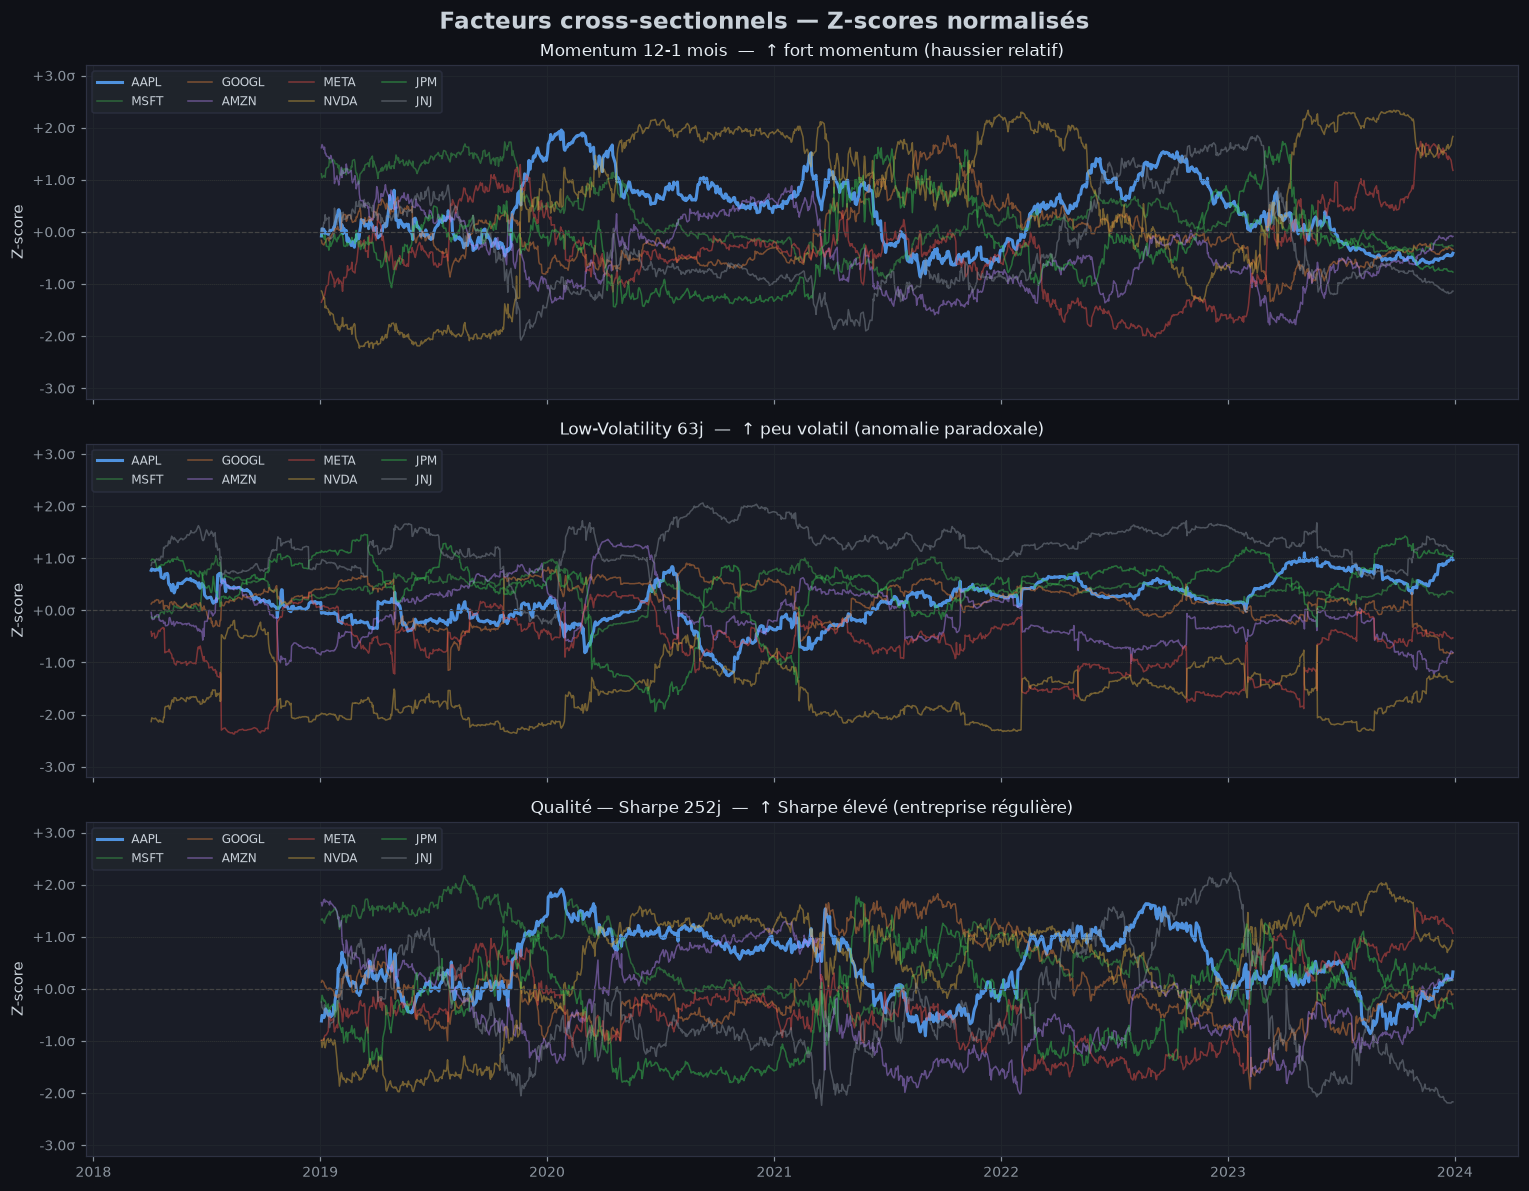

✓ Sauvegardé : reports/fig1_facteurs_cross_sectionnels.png


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
fig.suptitle('Facteurs cross-sectionnels — Z-scores normalisés', 
             fontsize=15, fontweight='bold', y=0.98)

factor_configs = [
    (mom,  'Momentum 12-1 mois',   PALETTE['blue'],   '↑ fort momentum (haussier relatif)'),
    (vol,  'Low-Volatility 63j',   PALETTE['purple'], '↑ peu volatil (anomalie paradoxale)'),
    (qual, 'Qualité — Sharpe 252j', PALETTE['teal'],  '↑ Sharpe élevé (entreprise régulière)'),
]

colors_tickers = [PALETTE['blue'], PALETTE['green'], PALETTE['orange'],
                  PALETTE['purple'], PALETTE['red'], PALETTE['yellow'],
                  PALETTE['teal'], PALETTE['gray']]

for ax, (factor_df, title, color, desc) in zip(axes, factor_configs):
    for i, ticker in enumerate(close_multi.columns):
        alpha = 0.85 if ticker == TICKER_MAIN else 0.45
        lw    = 2.0   if ticker == TICKER_MAIN else 1.0
        ax.plot(factor_df.index, factor_df[ticker],
                color=colors_tickers[i], alpha=alpha, lw=lw, label=ticker)

    ax.axhline(0,  color='#444', lw=0.8, ls='--')
    ax.axhline(1,  color='#333', lw=0.5, ls=':')
    ax.axhline(-1, color='#333', lw=0.5, ls=':')
    ax.set_ylabel('Z-score', fontsize=10)
    ax.set_title(f'{title}  —  {desc}', fontsize=11, pad=6)
    ax.legend(loc='upper left', ncol=4, fontsize=8)
    ax.set_ylim(-3.2, 3.2)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:+.1f}σ'))

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
fig.tight_layout()
plt.savefig('../reports/fig1_facteurs_cross_sectionnels.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('✓ Sauvegardé : reports/fig1_facteurs_cross_sectionnels.png')

### 2.1 Snapshot cross-sectionnel — classement des actifs aujourd'hui

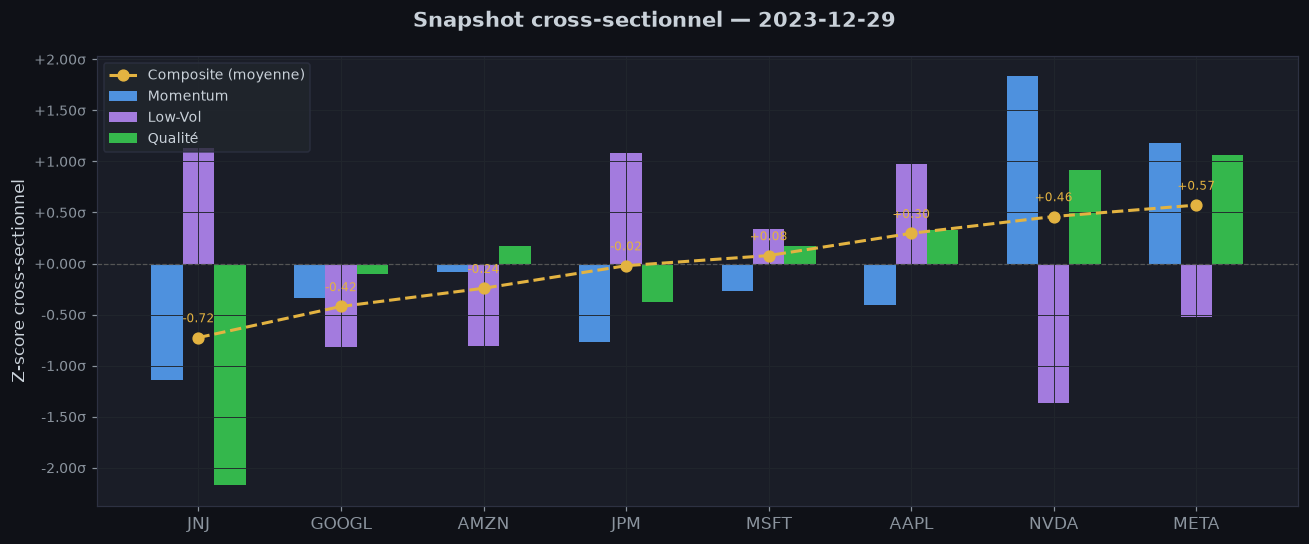

In [6]:
last_date = mom.dropna().index[-1]
snapshot  = pd.DataFrame({
    'Momentum':  mom.loc[last_date],
    'Low-Vol':   vol.loc[last_date],
    'Qualité':   qual.loc[last_date],
}).dropna()
snapshot['Composite'] = snapshot.mean(axis=1)
snapshot = snapshot.sort_values('Composite', ascending=True)

fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle(f'Snapshot cross-sectionnel — {last_date.date()}', 
             fontsize=14, fontweight='bold')

x     = np.arange(len(snapshot))
width = 0.22

bars_m = ax.bar(x - width,   snapshot['Momentum'], width, label='Momentum',
                color=PALETTE['blue'],   alpha=0.85)
bars_v = ax.bar(x,           snapshot['Low-Vol'],  width, label='Low-Vol',
                color=PALETTE['purple'], alpha=0.85)
bars_q = ax.bar(x + width,   snapshot['Qualité'],  width, label='Qualité',
                color=PALETTE['teal'],   alpha=0.85)

# Ligne composite
ax.plot(x, snapshot['Composite'], 'o--', color=PALETTE['yellow'],
        lw=2, ms=7, label='Composite (moyenne)', zorder=5)

ax.axhline(0, color='#555', lw=0.8, ls='--')
ax.set_xticks(x)
ax.set_xticklabels(snapshot.index, fontsize=11)
ax.set_ylabel('Z-score cross-sectionnel')
ax.legend(loc='upper left')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.2f}σ'))

# Annoter le composite
for i, (ticker, row) in enumerate(snapshot.iterrows()):
    ax.annotate(f"{row['Composite']:+.2f}",
                xy=(i, row['Composite']),
                xytext=(0, 10), textcoords='offset points',
                ha='center', fontsize=8, color=PALETTE['yellow'])

fig.tight_layout()
plt.savefig('../reports/fig2_snapshot_cross_sectionnel.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

## 3. Information Coefficient (IC) rolling

L'IC mesure **à quel point chaque signal prédit vraiment les rendements futurs**.  
IC = Spearman(signal_J, rendement_{J+1})  
- IC > 0.05 → signal avec de la valeur prédictive  
- IC < 0    → signal sans valeur (ou inversé)

In [7]:
# ── Calcul IC rolling pour chaque signal ─────────────────────────────────
ic_dict   = {}
icir_dict = {}

for name, sig in signals.items():
    ic_r  = compute_rolling_ic(sig.fillna(0), forward_returns, window=IC_WINDOW)
    icir  = compute_icir(ic_r, window=IC_WINDOW)
    ic_dict[name]   = ic_r
    icir_dict[name] = icir

ic_df   = pd.DataFrame(ic_dict)
icir_df = pd.DataFrame(icir_dict)

# Stats résumées
print('\nRésumé IC (fenêtre rolling 63j)\n')
print(f'{"Signal":20s}  {"IC moy":>8s}  {"IC std":>8s}  {"ICIR":>8s}  {"IC>0":>8s}')
print('─' * 60)
for name in signals:
    ic_c  = ic_dict[name].dropna()
    ic_m  = ic_c.mean()
    ic_s  = ic_c.std()
    icir_ = ic_m / ic_s if ic_s > 0 else 0
    pct   = (ic_c > 0).mean() * 100
    flag  = '🟢' if ic_m > 0.05 else ('🟡' if ic_m > 0 else '🔴')
    print(f'{flag} {name:18s}  {ic_m:+8.4f}  {ic_s:8.4f}  {icir_:+8.3f}  {pct:7.1f}%')


Résumé IC (fenêtre rolling 63j)

Signal                  IC moy    IC std      ICIR      IC>0
────────────────────────────────────────────────────────────
🔴 SMA 20/50            -0.0678    0.1081    -0.627     28.8%
🟡 RSI 14               +0.0421    0.0966    +0.436     65.1%
🔴 MACD 12/26/9         -0.0521    0.1183    -0.441     36.2%
🟢 Bollinger            +0.0727    0.1112    +0.653     71.7%


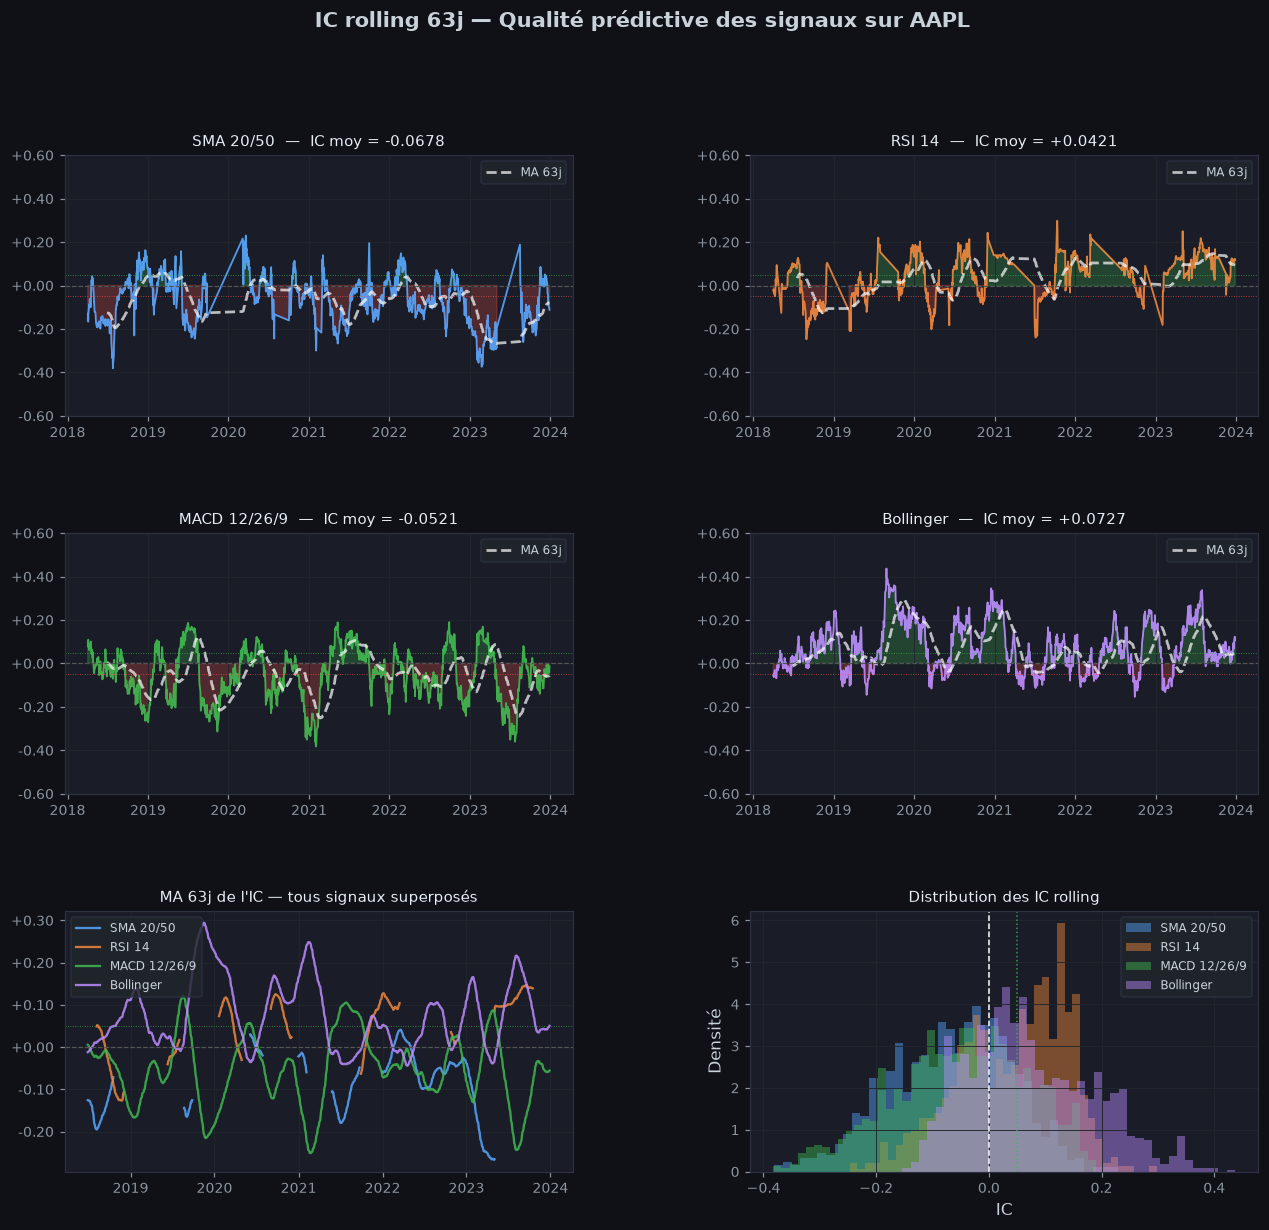

✓ Sauvegardé : reports/fig3_ic_rolling.png


In [8]:
colors_signals = [PALETTE['blue'], PALETTE['orange'], PALETTE['green'], PALETTE['purple']]

fig = plt.figure(figsize=(14, 12))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle(f'IC rolling {IC_WINDOW}j — Qualité prédictive des signaux sur {TICKER_MAIN}',
             fontsize=14, fontweight='bold', y=0.99)

signal_names = list(signals.keys())

# ── Subplot 1-4 : IC rolling par signal ──────────────────────────────────
axes_ic = [fig.add_subplot(gs[i // 2, i % 2]) for i in range(4)]

for ax, name, color in zip(axes_ic, signal_names, colors_signals):
    ic_s = ic_dict[name].dropna()

    # Zone colorée selon IC positif/négatif
    ax.fill_between(ic_s.index, ic_s, 0,
                    where=(ic_s >= 0), color=PALETTE['green'], alpha=0.25)
    ax.fill_between(ic_s.index, ic_s, 0,
                    where=(ic_s < 0),  color=PALETTE['red'],   alpha=0.25)

    ax.plot(ic_s.index, ic_s, color=color, lw=1.2, alpha=0.9)

    # Moyenne mobile de l'IC (signal de tendance de qualité)
    ic_ma = ic_s.rolling(63).mean()
    ax.plot(ic_ma.index, ic_ma, color='white', lw=1.8, alpha=0.7,
            ls='--', label='MA 63j')

    ax.axhline(0,     color='#555', lw=0.8, ls='--')
    ax.axhline(0.05,  color=PALETTE['green'], lw=0.6, ls=':', alpha=0.7)
    ax.axhline(-0.05, color=PALETTE['red'],   lw=0.6, ls=':', alpha=0.7)

    ic_mean = ic_s.mean()
    ax.set_title(f'{name}  —  IC moy = {ic_mean:+.4f}', fontsize=10)
    ax.set_ylim(-0.6, 0.6)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.2f}'))
    ax.legend(fontsize=8, loc='upper right')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ── Subplot 5 : IC rolling tous signaux superposés ───────────────────────
ax5 = fig.add_subplot(gs[2, 0])
for name, color in zip(signal_names, colors_signals):
    ic_ma63 = ic_dict[name].rolling(63).mean()
    ax5.plot(ic_ma63.index, ic_ma63, color=color, lw=1.5, label=name, alpha=0.85)
ax5.axhline(0,    color='#555', lw=0.8, ls='--')
ax5.axhline(0.05, color=PALETTE['green'], lw=0.6, ls=':', alpha=0.7)
ax5.set_title('MA 63j de l\'IC — tous signaux superposés', fontsize=10)
ax5.legend(fontsize=8)
ax5.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.2f}'))
ax5.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ── Subplot 6 : Distribution des IC ─────────────────────────────────────
ax6 = fig.add_subplot(gs[2, 1])
for name, color in zip(signal_names, colors_signals):
    ic_c = ic_dict[name].dropna()
    ax6.hist(ic_c, bins=40, color=color, alpha=0.45, label=name,
             density=True, edgecolor='none')
ax6.axvline(0, color='white', lw=1, ls='--')
ax6.axvline(0.05, color=PALETTE['green'], lw=1, ls=':', alpha=0.8)
ax6.set_title('Distribution des IC rolling', fontsize=10)
ax6.set_xlabel('IC')
ax6.set_ylabel('Densité')
ax6.legend(fontsize=8)

plt.savefig('../reports/fig3_ic_rolling.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('✓ Sauvegardé : reports/fig3_ic_rolling.png')

## 4. ICIR et poids dynamiques

**ICIR = IC_moyen / IC_std** → le Sharpe ratio du signal.  
Les poids dynamiques s'adaptent à la qualité récente de chaque signal.

In [9]:
# ── Calcul des poids IC et ICIR ───────────────────────────────────────────
weights_ic   = rolling_ic_weights(signals, forward_returns, window=IC_WINDOW)
weights_icir = rolling_icir_weights(signals, forward_returns,
                                    ic_window=IC_WINDOW, icir_window=IC_WINDOW)

print('Poids IC moyens sur la période :')
print(weights_ic.mean().round(3).to_string())
print('\nPoids ICIR moyens sur la période :')
print(weights_icir.mean().round(3).to_string())

Poids IC moyens sur la période :
SMA 20/50       0.099
RSI 14          0.229
MACD 12/26/9    0.221
Bollinger       0.450

Poids ICIR moyens sur la période :
SMA 20/50       0.052
RSI 14          0.155
MACD 12/26/9    0.186
Bollinger       0.608


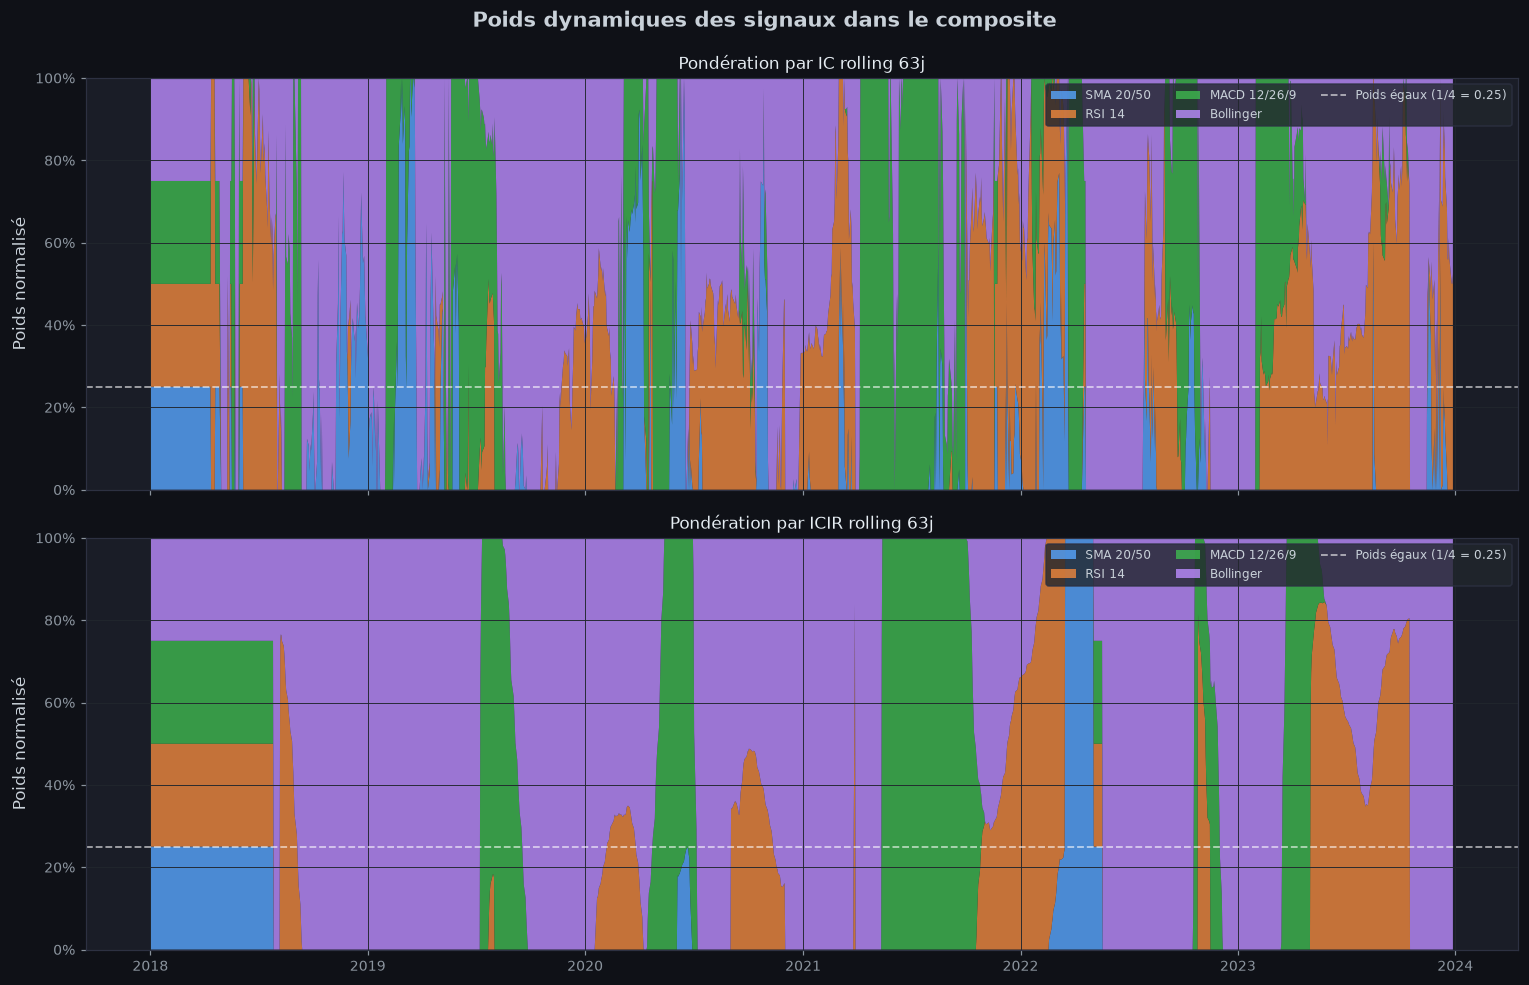

✓ Sauvegardé : reports/fig4_poids_dynamiques.png


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('Poids dynamiques des signaux dans le composite',
             fontsize=14, fontweight='bold', y=0.99)

for ax, (weights_df, title) in zip(axes, [
    (weights_ic,   f'Pondération par IC rolling {IC_WINDOW}j'),
    (weights_icir, f'Pondération par ICIR rolling {IC_WINDOW}j'),
]):
    w_clean = weights_df.dropna(how='all')

    # Stacked area chart
    ax.stackplot(
        w_clean.index,
        [w_clean[col].fillna(0) for col in w_clean.columns],
        labels=list(w_clean.columns),
        colors=colors_signals,
        alpha=0.80,
    )

    # Ligne de référence poids égaux
    n_sigs = len(signals)
    ax.axhline(1 / n_sigs, color='white', lw=1.2, ls='--', alpha=0.6,
               label=f'Poids égaux (1/{n_sigs} = {1/n_sigs:.2f})')

    ax.set_title(title, fontsize=11, pad=6)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Poids normalisé')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.legend(loc='upper right', ncol=3, fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

fig.tight_layout()
plt.savefig('../reports/fig4_poids_dynamiques.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('✓ Sauvegardé : reports/fig4_poids_dynamiques.png')

## 5. Rapport IC complet — tableau de qualité des signaux

In [11]:
report = signal_quality_report(signals, forward_returns, ic_window=IC_WINDOW)
print('\n── Rapport de qualité des signaux ──\n')
print(report.to_string())


── Rapport de qualité des signaux ──

              IC moyen  IC std    ICIR  IC > 0 (%)  Poids IC (%)  Poids ICIR (%)
Signal                                                                          
SMA 20/50      -0.0657  0.1090 -0.6026        29.5           0.0             0.0
RSI 14          0.0421  0.0966  0.4358        65.1          36.2            39.6
MACD 12/26/9   -0.0542  0.1187 -0.4564        35.4           0.0             0.0
Bollinger       0.0741  0.1113  0.6659        72.6          63.8            60.4


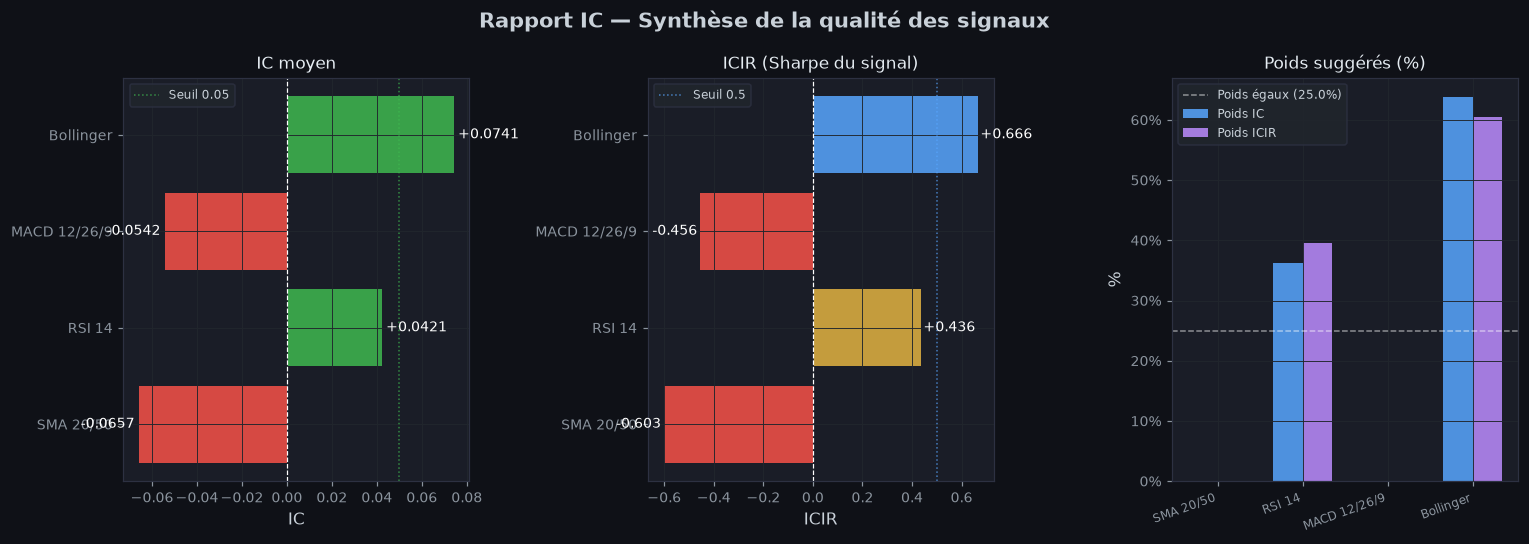

✓ Sauvegardé : reports/fig5_rapport_ic.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Rapport IC — Synthèse de la qualité des signaux',
             fontsize=14, fontweight='bold')

# ── Subplot 1 : IC moyen ─────────────────────────────────────────────────
ax = axes[0]
bar_colors = [PALETTE['green'] if v > 0 else PALETTE['red']
              for v in report['IC moyen']]
bars = ax.barh(report.index, report['IC moyen'], color=bar_colors, alpha=0.85)
ax.axvline(0,    color='white', lw=0.8, ls='--')
ax.axvline(0.05, color=PALETTE['green'], lw=1, ls=':', alpha=0.7, label='Seuil 0.05')
ax.set_title('IC moyen', fontsize=11)
ax.set_xlabel('IC')
ax.legend(fontsize=8)
for bar, val in zip(bars, report['IC moyen']):
    ax.text(val + (0.002 if val >= 0 else -0.002), bar.get_y() + bar.get_height()/2,
            f'{val:+.4f}', va='center', ha='left' if val >= 0 else 'right',
            fontsize=9, color='white')

# ── Subplot 2 : ICIR ─────────────────────────────────────────────────────
ax = axes[1]
icir_vals = report['ICIR']
bar_colors_icir = [PALETTE['blue'] if v > 0.5 else
                   (PALETTE['yellow'] if v > 0 else PALETTE['red'])
                   for v in icir_vals]
bars2 = ax.barh(report.index, icir_vals, color=bar_colors_icir, alpha=0.85)
ax.axvline(0,   color='white',         lw=0.8, ls='--')
ax.axvline(0.5, color=PALETTE['blue'], lw=1,   ls=':', alpha=0.7, label='Seuil 0.5')
ax.set_title('ICIR (Sharpe du signal)', fontsize=11)
ax.set_xlabel('ICIR')
ax.legend(fontsize=8)
for bar, val in zip(bars2, icir_vals):
    ax.text(val + (0.01 if val >= 0 else -0.01), bar.get_y() + bar.get_height()/2,
            f'{val:+.3f}', va='center', ha='left' if val >= 0 else 'right',
            fontsize=9, color='white')

# ── Subplot 3 : Poids suggérés IC vs ICIR ───────────────────────────────
ax = axes[2]
x    = np.arange(len(report))
w    = 0.35
ax.bar(x - w/2, report['Poids IC (%)'],   w, label='Poids IC',
       color=PALETTE['blue'],   alpha=0.85)
ax.bar(x + w/2, report['Poids ICIR (%)'], w, label='Poids ICIR',
       color=PALETTE['purple'], alpha=0.85)
ax.axhline(100 / len(report), color='white', lw=1, ls='--', alpha=0.5,
           label=f'Poids égaux ({100/len(report):.1f}%)')
ax.set_title('Poids suggérés (%)', fontsize=11)
ax.set_ylabel('%')
ax.set_xticks(x)
ax.set_xticklabels(report.index, rotation=20, ha='right', fontsize=8)
ax.legend(fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))

fig.tight_layout()
plt.savefig('../reports/fig5_rapport_ic.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('✓ Sauvegardé : reports/fig5_rapport_ic.png')

## 6. Backtest des 3 modes de pondération — Equity Curves

In [13]:
# ── Backtest des 3 modes ──────────────────────────────────────────────────
results_by_mode = {}

for mode in ['equal', 'ic', 'icir']:
    sig_combined = combine_signals(
        signals,
        weights_mode=mode,
        forward_returns=forward_returns,
        ic_window=IC_WINDOW,
    ).fillna(0)

    bt  = Backtester(df_main, initial_capital=INITIAL_CAPITAL)
    out = bt.run(sig_combined)
    results_by_mode[mode] = out

# Buy & Hold
bah_equity  = INITIAL_CAPITAL * (1 + df_main['returns'].fillna(0)).cumprod()
bah_metrics = full_metrics(df_main['returns'].fillna(0), bah_equity)

print('\n── Métriques par mode de pondération ──\n')
print(f'{"Mode":12s}  {"CAGR":>8s}  {"Sharpe":>8s}  {"Calmar":>8s}  {"MDD":>8s}  {"Capital":>10s}')
print('─' * 65)
for mode, out in results_by_mode.items():
    m = out['metrics']
    print(f'{mode:12s}  {m["CAGR (%)"] :>7.2f}%  {m["Sharpe"]:>8.2f}  '
          f'{m["Calmar"]:>8.2f}  {m["Max Drawdown (%)"] :>7.2f}%  '
          f'{m["Capital final (€)"]:>9.0f}€')
m = bah_metrics
print(f'{"Buy & Hold":12s}  {m["CAGR (%)"] :>7.2f}%  {m["Sharpe"]:>8.2f}  '
      f'{m["Calmar"]:>8.2f}  {m["Max Drawdown (%)"] :>7.2f}%  {"—":>10s}')


── Métriques par mode de pondération ──

Mode              CAGR    Sharpe    Calmar       MDD     Capital
─────────────────────────────────────────────────────────────────
equal           14.19%      0.74      0.48   -29.31%      22120€
ic              46.77%      2.11      2.88   -16.25%      99361€
icir            -3.11%     -0.01     -0.07   -46.82%       8279€
Buy & Hold      29.62%      0.98      0.77   -38.52%           —


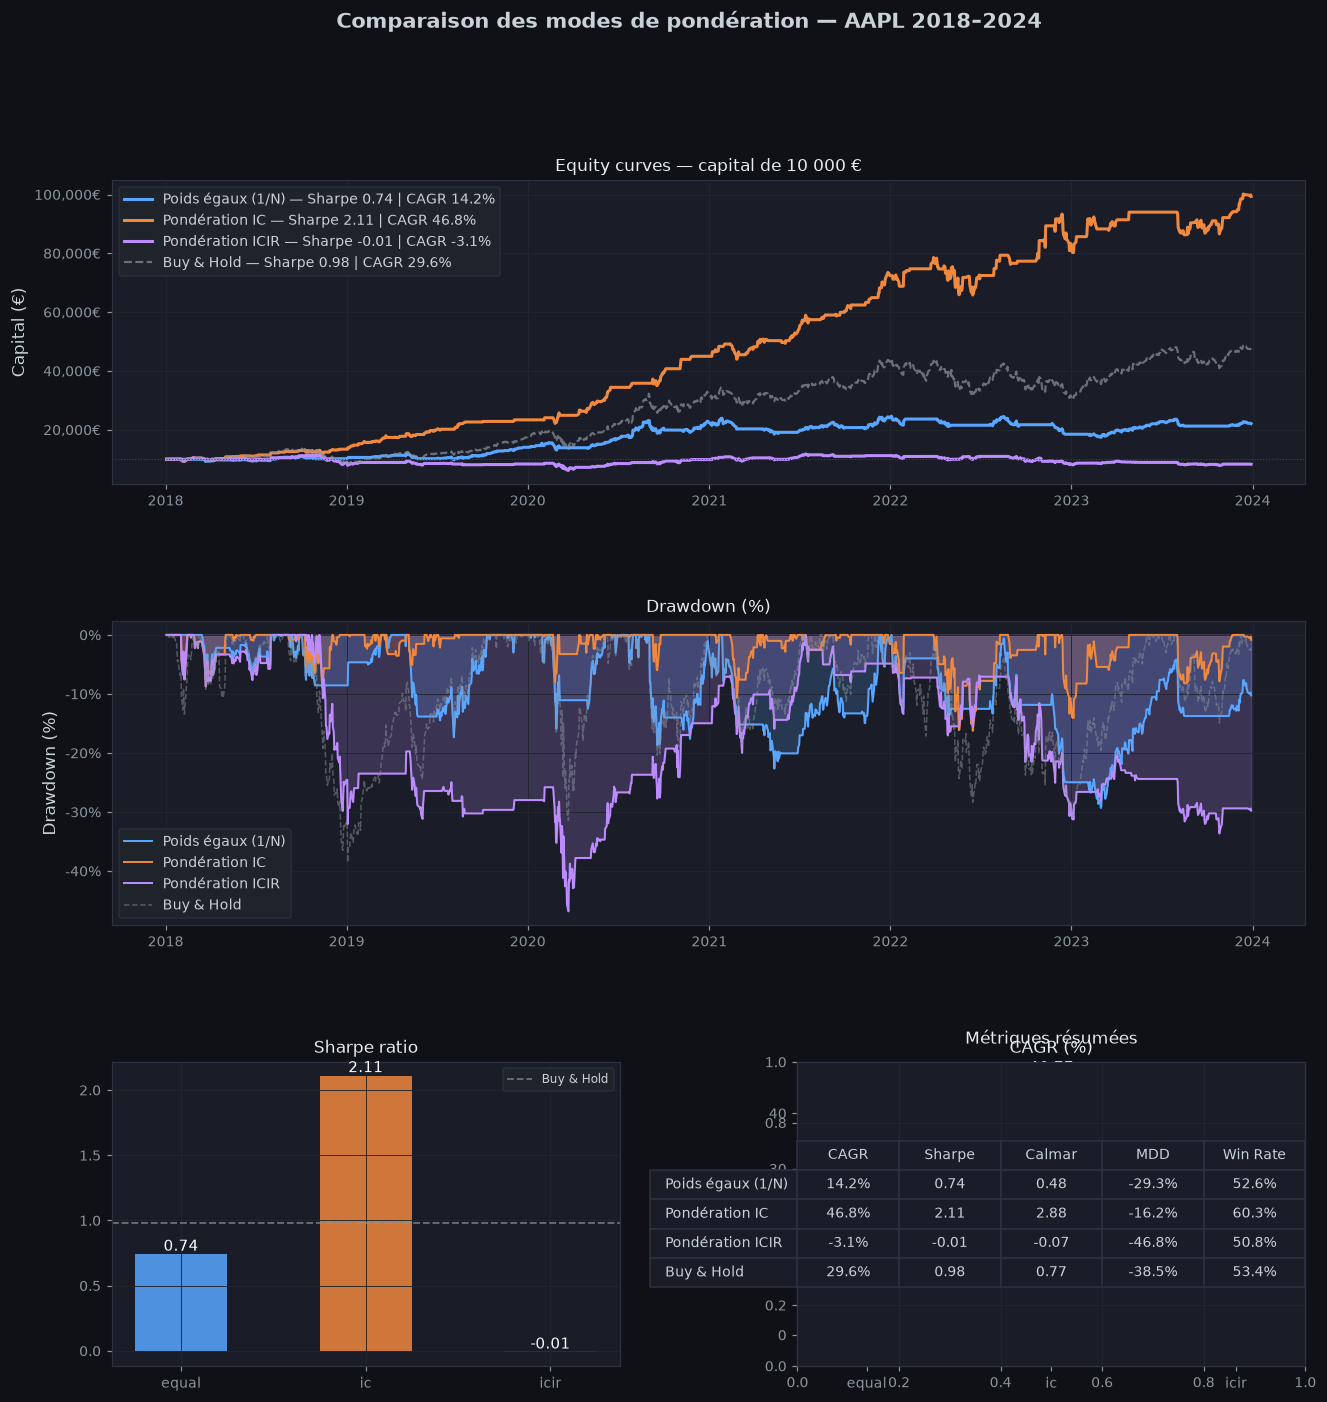

✓ Sauvegardé : reports/fig6_equity_curves_comparaison.png


In [14]:
mode_colors = {
    'equal': PALETTE['blue'],
    'ic':    PALETTE['orange'],
    'icir':  PALETTE['purple'],
}
mode_labels = {
    'equal': 'Poids égaux (1/N)',
    'ic':    'Pondération IC',
    'icir':  'Pondération ICIR',
}

fig = plt.figure(figsize=(14, 14))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle(f'Comparaison des modes de pondération — {TICKER_MAIN} {START[:4]}–{END[:4]}',
             fontsize=14, fontweight='bold', y=0.99)

# ── Subplot 1 : Equity curves ─────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
for mode, out in results_by_mode.items():
    eq = out['results']['equity_curve']
    m  = out['metrics']
    ax1.plot(eq.index, eq,
             color=mode_colors[mode], lw=2.0,
             label=f"{mode_labels[mode]} — Sharpe {m['Sharpe']:.2f} | "
                   f"CAGR {m['CAGR (%)']:.1f}%")

ax1.plot(bah_equity.index, bah_equity, color=PALETTE['gray'], lw=1.4,
         ls='--', alpha=0.7,
         label=f"Buy & Hold — Sharpe {bah_metrics['Sharpe']:.2f} | "
               f"CAGR {bah_metrics['CAGR (%)']:.1f}%")

ax1.axhline(INITIAL_CAPITAL, color='#444', lw=0.7, ls=':')
ax1.set_title('Equity curves — capital de 10 000 €', fontsize=11)
ax1.set_ylabel('Capital (€)')
ax1.legend(fontsize=9)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}€'))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ── Subplot 2 : Drawdown ──────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, :])
for mode, out in results_by_mode.items():
    eq  = out['results']['equity_curve']
    mdd = (eq / eq.cummax() - 1) * 100
    ax2.fill_between(mdd.index, mdd, 0,
                     color=mode_colors[mode], alpha=0.20)
    ax2.plot(mdd.index, mdd, color=mode_colors[mode], lw=1.3,
             label=mode_labels[mode])

# Drawdown Buy & Hold
mdd_bah = (bah_equity / bah_equity.cummax() - 1) * 100
ax2.plot(mdd_bah.index, mdd_bah, color=PALETTE['gray'], lw=1,
         ls='--', alpha=0.5, label='Buy & Hold')

ax2.set_title('Drawdown (%)', fontsize=11)
ax2.set_ylabel('Drawdown (%)')
ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ── Subplots 3-5 : Métriques comparées ───────────────────────────────────
metrics_to_plot = [
    ('Sharpe',            'Sharpe ratio',      True),
    ('CAGR (%)',          'CAGR (%)',           True),
    ('Max Drawdown (%)',  'Max Drawdown (%)',   False),
]

bah_vals = {
    'Sharpe':           bah_metrics['Sharpe'],
    'CAGR (%)':         bah_metrics['CAGR (%)'],
    'Max Drawdown (%)': bah_metrics['Max Drawdown (%)'],
}

for idx, (metric, label, higher_is_better) in enumerate(metrics_to_plot):
    ax = fig.add_subplot(gs[2, idx % 2]) if idx < 2 else fig.add_subplot(gs[2, 1])
    if idx == 2:
        ax = fig.add_subplot(gs[2, :])
        ax.set_visible(False)
        break

    vals   = [results_by_mode[m]['metrics'][metric] for m in results_by_mode]
    modes_ = list(results_by_mode.keys())
    colors_bar = [mode_colors[m] for m in modes_]

    bars_ = ax.bar(modes_, vals, color=colors_bar, alpha=0.85, width=0.5)
    ax.axhline(bah_vals[metric], color=PALETTE['gray'], lw=1.2, ls='--',
               alpha=0.7, label='Buy & Hold')
    ax.set_title(label, fontsize=11)
    ax.legend(fontsize=8)
    for bar_, val in zip(bars_, vals):
        ax.text(bar_.get_x() + bar_.get_width()/2, val,
                f'{val:.2f}', ha='center', va='bottom', fontsize=10, color='white')

# Subplot 3b : tableau métriques
ax_tab = fig.add_subplot(gs[2, 1])
ax_tab.axis('off')
rows_tab   = []
col_labels = ['CAGR', 'Sharpe', 'Calmar', 'MDD', 'Win Rate']
row_labels = list(mode_labels.values()) + ['Buy & Hold']
for mode, out in results_by_mode.items():
    m = out['metrics']
    rows_tab.append([f"{m['CAGR (%)']:.1f}%", f"{m['Sharpe']:.2f}",
                     f"{m['Calmar']:.2f}",
                     f"{m['Max Drawdown (%)']:.1f}%",
                     f"{m['Win Rate (%)']:.1f}%"])
m = bah_metrics
rows_tab.append([f"{m['CAGR (%)']:.1f}%", f"{m['Sharpe']:.2f}",
                 f"{m['Calmar']:.2f}",
                 f"{m['Max Drawdown (%)']:.1f}%",
                 f"{m['Win Rate (%)']:.1f}%"])

table = ax_tab.table(
    cellText=rows_tab, rowLabels=row_labels, colLabels=col_labels,
    loc='center', cellLoc='center',
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
for (row, col), cell in table.get_celld().items():
    cell.set_facecolor('#1a1d27')
    cell.set_edgecolor('#2d3142')
    cell.set_text_props(color='#c9d1d9')
ax_tab.set_title('Métriques résumées', fontsize=11, pad=12)

plt.savefig('../reports/fig6_equity_curves_comparaison.png', dpi=130,
            bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print('✓ Sauvegardé : reports/fig6_equity_curves_comparaison.png')

## 7. Heatmap de robustesse — SMA crossover

Un pic isolé = stratégie fragile (overfittée).  
Un **plateau élevé** = stratégie robuste (les résultats sont stables autour des paramètres optimaux).

In [15]:
from backtester.validation import robustness_surface

fast_values = [5, 10, 15, 20, 30, 40, 50]
slow_values = [30, 50, 75, 100, 150, 200]

print('Calcul de la surface de robustesse (peut prendre ~30s)...')
surface_sharpe = robustness_surface(
    df=df_main,
    signal_func=sma_crossover,
    param_x='fast', param_x_values=fast_values,
    param_y='slow', param_y_values=slow_values,
    metric='Sharpe',
)

surface_cagr = robustness_surface(
    df=df_main,
    signal_func=sma_crossover,
    param_x='fast', param_x_values=fast_values,
    param_y='slow', param_y_values=slow_values,
    metric='CAGR (%)',
)

# Masquer fast >= slow (invalide)
for df_surf in [surface_sharpe, surface_cagr]:
    for slow in df_surf.index:
        for fast in df_surf.columns:
            if fast >= slow:
                df_surf.loc[slow, fast] = np.nan

print('✓ Surface calculée')
print(surface_sharpe.to_string())

Calcul de la surface de robustesse (peut prendre ~30s)...
✓ Surface calculée
fast    5     10    15    20    30    40    50
slow                                          
30    1.38  1.04  1.17  1.14   NaN   NaN   NaN
50    1.17  0.98  1.06  0.89  0.80  0.55   NaN
75    0.99  1.08  0.84  0.77  0.76  0.84  0.77
100   1.04  0.66  0.68  0.69  0.64  0.69  0.81
150   0.61  0.66  0.72  0.59  0.48  0.56  0.61
200   0.72  0.79  0.66  0.59  0.70  0.72  0.63


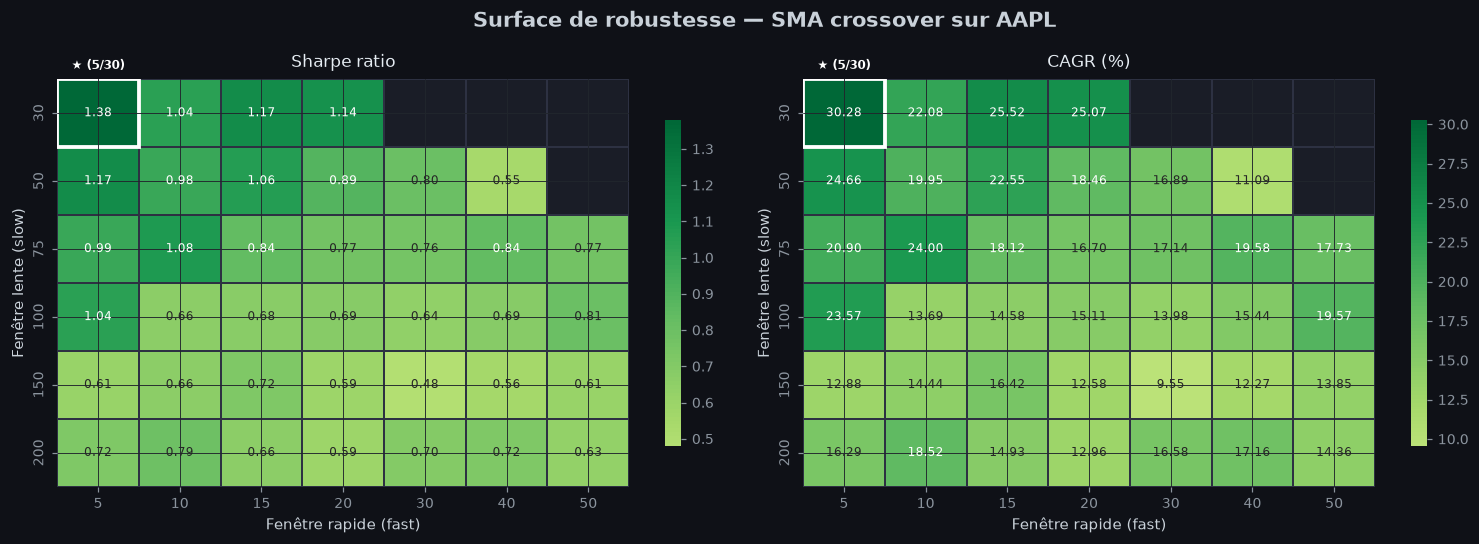

✓ Sauvegardé : reports/fig7_heatmap_robustesse.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Surface de robustesse — SMA crossover sur {TICKER_MAIN}',
             fontsize=14, fontweight='bold')

for ax, (surface, title, cmap) in zip(axes, [
    (surface_sharpe, 'Sharpe ratio',  'RdYlGn'),
    (surface_cagr,   'CAGR (%)',      'RdYlGn'),
]):
    mask = surface.isna()
    sns.heatmap(
        surface,
        ax=ax,
        annot=True,
        fmt='.2f',
        cmap=cmap,
        center=0,
        mask=mask,
        linewidths=0.3,
        linecolor='#2d3142',
        annot_kws={'size': 8},
        cbar_kws={'shrink': 0.8},
    )
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_xlabel('Fenêtre rapide (fast)', fontsize=10)
    ax.set_ylabel('Fenêtre lente (slow)',  fontsize=10)
    ax.tick_params(labelsize=9)

    # Marquer le meilleur paramètre
    best_idx = surface.stack().idxmax()
    best_row = surface.index.get_loc(best_idx[0])
    best_col = surface.columns.get_loc(best_idx[1])
    ax.add_patch(plt.Rectangle((best_col, best_row), 1, 1,
                                fill=False, edgecolor='white', lw=2.5))
    ax.text(best_col + 0.5, best_row - 0.15,
            f'★ ({best_idx[1]}/{best_idx[0]})',
            ha='center', fontsize=8, color='white', fontweight='bold')

fig.tight_layout()
plt.savefig('../reports/fig7_heatmap_robustesse.png', dpi=130, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('✓ Sauvegardé : reports/fig7_heatmap_robustesse.png')

## 8. Analyse alpha — régression CAPM

`R_strat = α + β × R_marché + ε`  
- **α > 0 et p < 0.05** → valeur ajoutée réelle au-delà du marché  
- **β** → exposition directionnelle au marché (1 = suit le marché, <1 = défensif)

In [17]:
if mkt_ret is not None:
    print('── Régression CAPM par mode de pondération ──\n')
    print(f'{"Mode":12s}  {"Alpha/an":>10s}  {"Beta":>8s}  {"R²":>6s}  '
          f'{"p-value":>8s}  {"Significatif":>12s}')
    print('─' * 65)

    capm_results = {}
    for mode, out in results_by_mode.items():
        r_strat = out['results']['strategy_returns']
        fa      = fama_french_alpha(r_strat, mkt_ret)
        capm_results[mode] = fa
        sig = '✓ OUI' if fa.get('alpha significatif') else '✗ non'
        print(f"{mode:12s}  {fa['alpha (annualisé %)']:>+9.2f}%  "
              f"{fa['beta']:>8.3f}  {fa['R²']:>6.4f}  "
              f"{fa['p-value alpha']:>8.4f}  {sig:>12s}")
else:
    print('SPY non disponible — analyse CAPM ignorée.')
    capm_results = {}

── Régression CAPM par mode de pondération ──

Mode            Alpha/an      Beta      R²   p-value  Significatif
─────────────────────────────────────────────────────────────────
equal             +9.44%     0.450  0.1947    0.0000         ✓ OUI
ic               +34.43%     0.433  0.2160    0.0000         ✓ OUI
icir             -11.23%     0.824  0.4903    0.0000         ✓ OUI


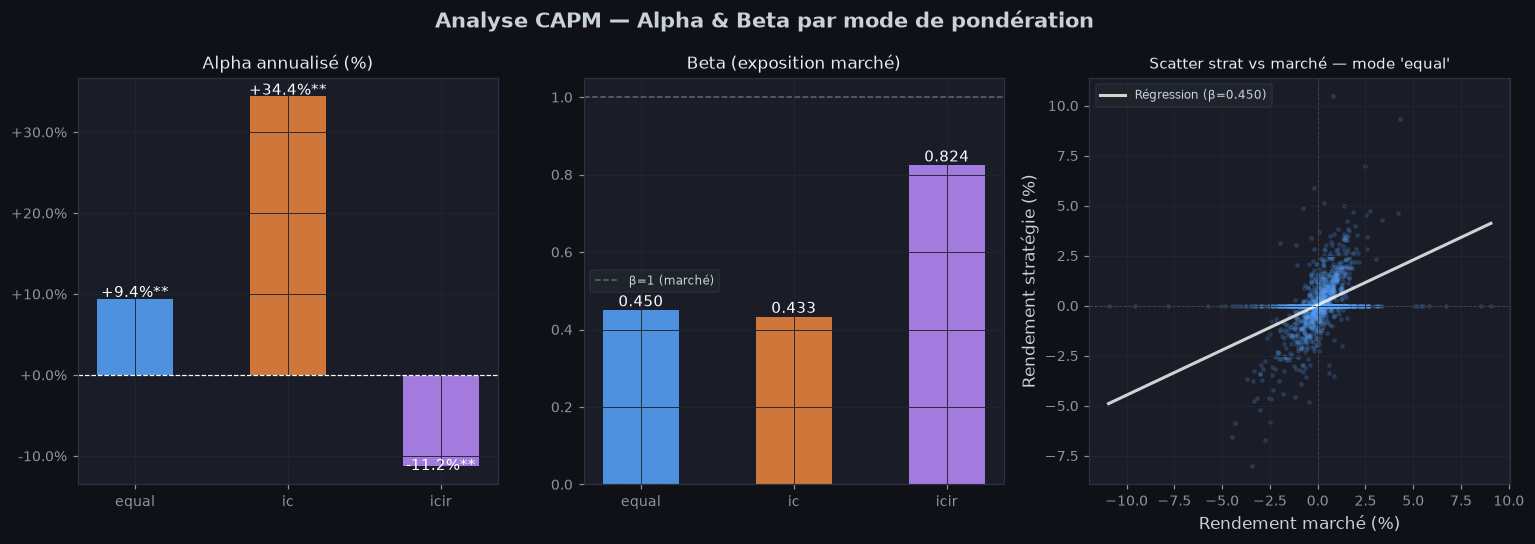

✓ Sauvegardé : reports/fig8_capm_alpha.png


In [18]:
if capm_results and mkt_ret is not None:
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    fig.suptitle('Analyse CAPM — Alpha & Beta par mode de pondération',
                 fontsize=14, fontweight='bold')

    modes_list = list(capm_results.keys())
    colors_bar = [mode_colors[m] for m in modes_list]

    # Alpha
    alphas = [capm_results[m]['alpha (annualisé %)'] for m in modes_list]
    axes[0].bar(modes_list, alphas, color=colors_bar, alpha=0.85, width=0.5)
    axes[0].axhline(0, color='white', lw=0.8, ls='--')
    axes[0].set_title('Alpha annualisé (%)', fontsize=11)
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.1f}%'))
    for i, (mode, val) in enumerate(zip(modes_list, alphas)):
        p = capm_results[mode]['p-value alpha']
        star = '**' if p < 0.01 else ('*' if p < 0.05 else '')
        axes[0].text(i, val + (0.2 if val >= 0 else -0.5),
                     f'{val:+.1f}%{star}', ha='center', fontsize=10, color='white')

    # Beta
    betas = [capm_results[m]['beta'] for m in modes_list]
    axes[1].bar(modes_list, betas, color=colors_bar, alpha=0.85, width=0.5)
    axes[1].axhline(1.0, color=PALETTE['gray'], lw=1, ls='--', alpha=0.6, label='β=1 (marché)')
    axes[1].axhline(0.0, color='white', lw=0.7, ls='--', alpha=0.4)
    axes[1].set_title('Beta (exposition marché)', fontsize=11)
    axes[1].legend(fontsize=8)
    for i, (mode, val) in enumerate(zip(modes_list, betas)):
        axes[1].text(i, val + 0.01, f'{val:.3f}', ha='center', fontsize=10, color='white')

    # Scatter strat vs marché (mode 'equal' uniquement)
    ax3 = axes[2]
    mode_scatter = 'equal'
    r_strat = results_by_mode[mode_scatter]['results']['strategy_returns']
    combined_df = pd.DataFrame({'strat': r_strat, 'mkt': mkt_ret}).dropna()

    ax3.scatter(combined_df['mkt'] * 100, combined_df['strat'] * 100,
                color=mode_colors[mode_scatter], alpha=0.15, s=5)

    # Droite de régression
    slope, intercept, *_ = stats.linregress(combined_df['mkt'], combined_df['strat'])
    x_line = np.linspace(combined_df['mkt'].min(), combined_df['mkt'].max(), 100)
    ax3.plot(x_line * 100, (intercept + slope * x_line) * 100,
             color='white', lw=2, alpha=0.8, label=f'Régression (β={slope:.3f})')
    ax3.axhline(0, color='#444', lw=0.6, ls='--')
    ax3.axvline(0, color='#444', lw=0.6, ls='--')
    ax3.set_title(f'Scatter strat vs marché — mode \'{mode_scatter}\'', fontsize=10)
    ax3.set_xlabel('Rendement marché (%)')
    ax3.set_ylabel('Rendement stratégie (%)')
    ax3.legend(fontsize=8)

    fig.tight_layout()
    plt.savefig('../reports/fig8_capm_alpha.png', dpi=130, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.show()
    print('✓ Sauvegardé : reports/fig8_capm_alpha.png')

## 9. Synthèse finale — récapitulatif des figures produites

In [19]:
import os

print('\n' + '═'*60)
print('SYNTHÈSE SÉANCE 8 — Figures produites')
print('═'*60)

figures = [
    ('fig1_facteurs_cross_sectionnels.png', 'Facteurs momentum / low-vol / qualité dans le temps'),
    ('fig2_snapshot_cross_sectionnel.png',  'Classement cross-sectionnel des actifs (dernière date)'),
    ('fig3_ic_rolling.png',                 'IC rolling + distribution par signal'),
    ('fig4_poids_dynamiques.png',           'Poids IC et ICIR dynamiques (stacked area)'),
    ('fig5_rapport_ic.png',                 'Rapport qualité : IC moyen, ICIR, poids suggérés'),
    ('fig6_equity_curves_comparaison.png',  'Equity curves + drawdown + métriques comparées'),
    ('fig7_heatmap_robustesse.png',         'Heatmap Sharpe/CAGR vs paramètres SMA'),
    ('fig8_capm_alpha.png',                 'Alpha, Beta et scatter strat vs marché'),
]

for fname, desc in figures:
    path   = f'../reports/{fname}'
    exists = '✓' if os.path.exists(path) else '✗'
    print(f'  {exists}  {fname:<45s}  {desc}')

print('\n── Commit suggéré ──')
print('  git add backtester/factors.py backtester/combination.py')
print('  git add notebooks/03_factor_analysis.ipynb')
print('  git add tests/test_factors.py tests/test_combination.py')
print('  git commit -m "feat: factor analysis notebook with 8 visuals"')
print()
print('── Ouvrir dans le navigateur (WSL) ──')
print('  explorer.exe ..\\reports\\fig6_equity_curves_comparaison.png')
print('  explorer.exe ..\\reports\\fig7_heatmap_robustesse.png')


════════════════════════════════════════════════════════════
SYNTHÈSE SÉANCE 8 — Figures produites
════════════════════════════════════════════════════════════
  ✓  fig1_facteurs_cross_sectionnels.png            Facteurs momentum / low-vol / qualité dans le temps
  ✓  fig2_snapshot_cross_sectionnel.png             Classement cross-sectionnel des actifs (dernière date)
  ✓  fig3_ic_rolling.png                            IC rolling + distribution par signal
  ✓  fig4_poids_dynamiques.png                      Poids IC et ICIR dynamiques (stacked area)
  ✓  fig5_rapport_ic.png                            Rapport qualité : IC moyen, ICIR, poids suggérés
  ✓  fig6_equity_curves_comparaison.png             Equity curves + drawdown + métriques comparées
  ✓  fig7_heatmap_robustesse.png                    Heatmap Sharpe/CAGR vs paramètres SMA
  ✓  fig8_capm_alpha.png                            Alpha, Beta et scatter strat vs marché

── Commit suggéré ──
  git add backtester/factors.py backteste